<center><b><span style="font-size:28pt">Apanasov's wild sphere</span></b></center>

This model reconstructs the front projection in Figure 5 from the drawing. It shows a finite stage of the geometry. The full group action and the limit set $L(G)$ lie beyond this reconstruction.

[B. N. Apanasov, *Group actions, Teichmüller spaces and cobordisms*](https://arxiv.org/pdf/1611.00432)

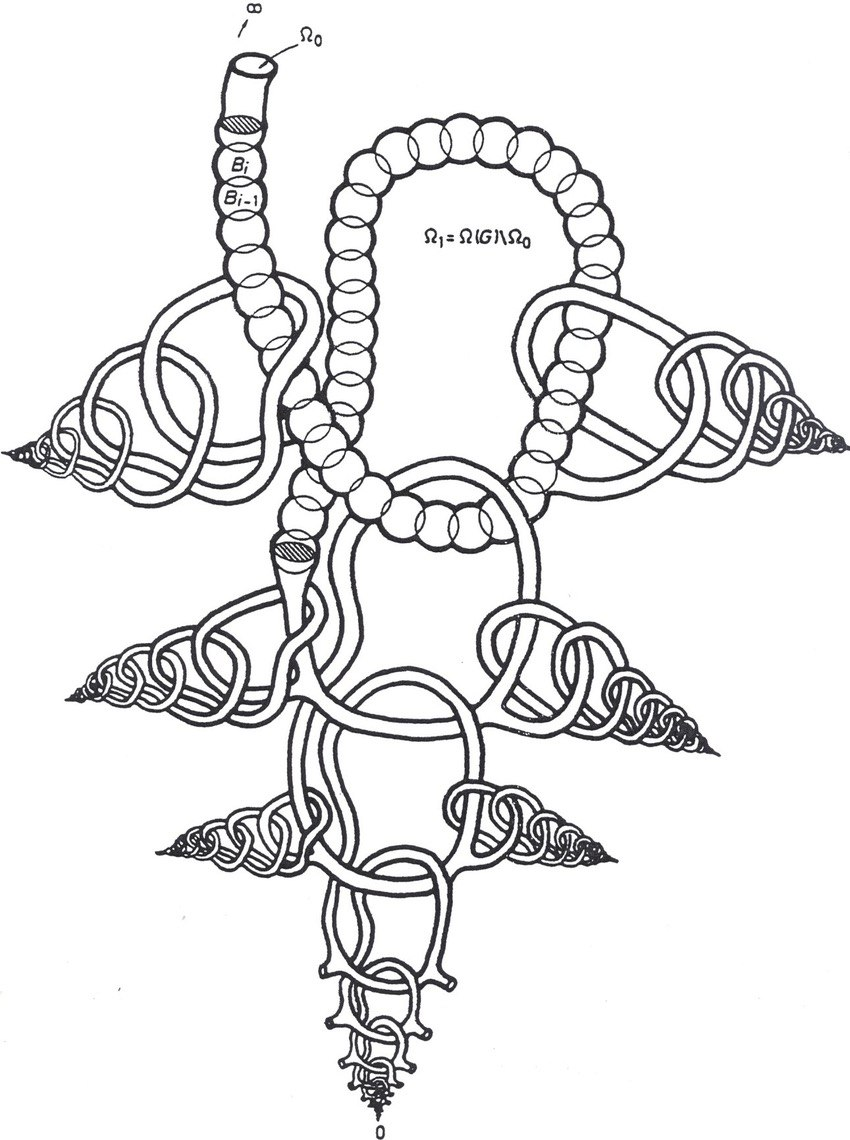

*Figure 5. Wild ball covering of a hyperbolic 4-cobordism boundary.*

### Construct the strands

The $x,y$ coordinates come from the drawing, with $y$ increasing downward. Consecutive main loops shrink by a factor of $0.72$. Each loop passes in front of the preceding loop on the right and behind it on the left.

The first turn of a side chain wraps around a main strand. Five open elliptical turns follow, shrinking by a factor of $0.64$ and alternating in depth at the crossings.

In [ ]:
# %pip install osqp

In [ ]:
# %pip install av

In [12]:
import numpy as np
import osqp
from PIL import Image, ImageDraw, ImageFont
from scipy.interpolate import CubicSpline
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix, diags, eye, vstack
from IPython.display import display
from dataclasses import dataclass
from functools import lru_cache
from io import BytesIO
import av
from IPython.display import Video

In [2]:
WIDTH, HEIGHT = 940, 1190
OFFSET = np.array([45.0, 20.0, 0.0])
IVORY = np.array([249, 246, 238])
TEAL = (49, 137, 143)
AMBER = (178, 96, 39)
COPPER = (223, 132, 54)

# Coordinates are (horizontal, vertical down, depth toward the viewer)
UPPER = np.array([[253, 65, 10], [243, 96, 10], [240, 131, 12], [239, 168, 15], [241, 206, 18], [247, 249, 23], [258, 286, 30], [272, 327, 36], [300, 380, 40], [324, 435, 42], [365, 493, 40],
                  [402, 518, 35], [468, 526, 27], [515, 510, 18], [544, 470, 9], [568, 405, 1], [584, 351, -7], [596, 297, -12], [595, 249, -13], [575, 197, -15], [544, 159, -17], [506, 142, -16],
                  [462, 138, -15], [416, 144, -17], [379, 160, -20], [359, 192, -24], [353, 231, -32], [351, 279, -36], [352, 326, -38], [347, 385, -41], [331, 449, -42], [308, 502, -36], [294, 548, -17]], dtype=float)
LOWER = np.array([[294, 548, -17], [295, 595, -15], [289, 642, -11], [292, 675, -8], [319, 706, 1], [368, 723, 11], [425, 725, 16], [467, 717, 22], [496, 690, 21], [518, 649, 16], [529, 607, 10], [530, 567, 5],
                  [516, 522, -2], [490, 487, -10], [449, 471, -19], [413, 480, -27], [374, 505, -31], [346, 540, -35], [341, 581, -38], [344, 626, -42], [335, 660, -45], [320, 687, -38], [316, 705, -29]], dtype=float)

@dataclass
class Strip:
    points: np.ndarray
    radius: np.ndarray
    start: float
    end: float
    color: tuple
    label: str
    parent: int | None = None
    attach: int | None = None
    turns: tuple = ()

    def visible(self, t):
        if t <= self.start:
            return self.points[:0], self.radius[:0]
        if t >= self.end:
            return self.points, self.radius
        location = (len(self.points) - 1) * (t - self.start) / (self.end - self.start)
        index = int(location)
        weight = location - index
        tip = (1 - weight) * self.points[index] + weight * self.points[index + 1]
        size = (1 - weight) * self.radius[index] + weight * self.radius[index + 1]
        return np.vstack((self.points[: index + 1], tip)), np.r_[self.radius[: index + 1], size]

def smooth_path(anchors, spacing=0.95):
    dist = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(anchors, axis=0), axis=1))]
    spline = CubicSpline(dist, anchors, axis=0, bc_type="natural")
    sample = spline(np.linspace(0, dist[-1], max(6, int(dist[-1] / spacing))))
    true_dist = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(sample, axis=0), axis=1))]
    uniform = np.linspace(0, true_dist[-1], len(sample))
    return np.column_stack([np.interp(uniform, true_dist, c) for c in sample.T])

def sample_strand(points, widths, spacing=0.85, turns=()):
    distance = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(points, axis=0), axis=1))]
    arc = np.linspace(0, distance[-1], max(8, int(np.ceil(distance[-1] / spacing)) + 1))
    mapped = ()
    if turns:
        stops = distance[np.asarray(turns)]
        arc = np.unique(np.r_[arc, stops.ravel()])
        mapped = tuple(map(tuple, np.searchsorted(arc, stops)))
    path = np.column_stack([np.interp(arc, distance, c) for c in points.T])
    return path, np.interp(arc, distance, widths), mapped

def crossing_parameters(a, b):
    """Pairs of arc parameters where two projected polylines cross"""
    def det(u, v):
        return u[:, 0] * v[:, 1] - u[:, 1] * v[:, 0]
    midpoint_a = (a[:-1, :2] + a[1:, :2]) / 2
    midpoint_b = (b[:-1, :2] + b[1:, :2]) / 2
    reach = (np.linalg.norm(np.diff(a[:, :2], axis=0), axis=1).max()
             + np.linalg.norm(np.diff(b[:, :2], axis=0), axis=1).max()) / 2 + 1e-8
    candidates = cKDTree(midpoint_a).query_ball_tree(cKDTree(midpoint_b), reach)
    i = np.repeat(np.arange(len(candidates)), [len(js) for js in candidates])
    j = np.concatenate(candidates).astype(int)
    da, db = a[i + 1, :2] - a[i, :2], b[j + 1, :2] - b[j, :2]
    delta = b[j, :2] - a[i, :2]
    denominator = det(da, db)
    mask = np.abs(denominator) > 1e-10
    i, j, da, db, delta, denominator = [v[mask] for v in (i, j, da, db, delta, denominator)]
    x, y = det(delta, db) / denominator, det(delta, da) / denominator
    mask = (0 <= x) & (x < 1) & (0 <= y) & (y < 1)
    result = np.column_stack((i[mask] + x[mask], j[mask] + y[mask]))
    return result[np.argsort(result[:, 0])]

def value_at(data, index):
    return np.interp(index, np.arange(len(data)), data)

def lift_main(points, radii, parent, scale):
    """The right shoulder comes in front, the left returns behind"""
    crossings = crossing_parameters(points, parent.points)
    crossings = crossings[crossings[:, 0] > 5 * scale]
    assert len(crossings) == 2, "Consecutive main loops must cross twice in projection"
    for (s, p), sign in zip(crossings, (1, -1)):
        z = value_at(parent.points[:, 2], p)
        required = value_at(radii, s) + value_at(parent.radius, p)
        target = z + sign * (2.1 * required + 5 * scale)
        delta = target - value_at(points[:, 2], s)
        # Plateau at the crossing, cosine shoulders away from it
        distance = abs(np.arange(len(points)) - s)
        u = np.clip((distance - 23 * scale) / (43 * scale), 0, 1)
        points[:, 2] += delta * (0.5 + 0.5 * np.cos(np.pi * u))
    return sample_strand(points, radii)[:2]


def side_tail(hook, tip_xy, direction, size, turns=5):
    """Nested open ellipses, alternating in depth through the preceding one"""
    root = hook[-1]
    horizontal = direction * (tip_xy[0] - root[0])
    ratio, pitch, phase, gap = 0.64, 1.18, -0.15, 0.29
    total = pitch * (1 - ratio**turns) / (1 - ratio)
    radius = horizontal / (total - np.cos(phase))
    if radius <= 0: raise ValueError("Side turns must narrow toward the tip")
    vertical = 1.13
    baseline = root[1] - vertical * radius * np.sin(phase)
    slope = (tip_xy[1] - baseline) / horizontal
    theta = np.linspace(phase, phase + 2 * np.pi - gap, 151)
    local = -radius * np.cos(phase)
    curves = []
    widths = []
    turn_bounds = []
    for i in range(turns):
        r = radius * ratio**i
        u = local + r * np.cos(theta)
        v = vertical * r * np.sin(theta)
        x = root[0] + direction * u
        y = baseline + slope * u + v
        z = np.full_like(x, root[2])
        curves.append(np.column_stack((x, y, z)))
        widths.append(np.full(len(theta), max(0.46, min(7.6 * size, 0.12 * radius) * ratio**i)))
        local += pitch * r
    prior = hook
    plane = None
    for i, curve in enumerate(curves):
        along = direction * (curve[:, 0] - root[0])
        across = curve[:, 1] - baseline - slope * along
        chart = np.column_stack((np.ones(len(curve)), along, across))
        crossings = crossing_parameters(curve, prior)
        if i == 0:
            crossings = crossings[crossings[:, 0] > 3]
        if len(crossings) < 2:
            raise ValueError("Consecutive side turns must cross twice in projection")
        a, b = crossings.T
        transverse = value_at(across, a)
        selected = [np.argmin(transverse), np.argmax(transverse)]
        a, b = a[selected], b[selected]
        margin = max(4.2 * widths[i][0], 0.58 * radius * ratio**i)
        if i == 0:
            positions = [value_at(col, a) for col in chart.T]
            constraints = np.vstack((chart[0], np.column_stack(positions)))
            target = np.r_[root[2], value_at(prior[:, 2], b) + [margin, -margin]]
            plane = np.linalg.solve(constraints, target)
        else:
            a0, a1 = transverse[selected]
            slope_z = (-1.0) ** i * (-2 * margin) / (a1 - a0)
            plane = plane + np.array([-slope_z * (a0 + a1) / 2, 0, slope_z])
        curve[:, 2] = chart @ plane
        prior = curve
    curves[0][0] = root
    for i, (curve, width) in enumerate(zip(curves, widths)):
        if i:
            old = curves[i - 1][-1]
            new = curve[0]
            # Connect the two open ends through the upper gap
            v = np.linspace(0, 1, 19)[1:-1, None]
            bridge = old + (new - old) * v
            bridge[:, 1] -= 0.49 * radius * ratio ** (i - 1) * np.sin(np.pi * v[:, 0])
            bridge[:, 2] += 0.57 * radius * ratio ** (i - 1) * np.sin(np.pi * v[:, 0])
            parts.append(bridge)
            sizes.append(np.linspace(widths[i - 1][-1], width[0], 19)[1:-1])
        else:
            parts, sizes = [], []
        begin = sum(len(p) for p in parts)
        turn_bounds.append((begin, begin + len(curve) - 1))
        parts.append(curve)
        sizes.append(width)
    end = parts[-1][-1]
    u = np.linspace(0, 1, 21)[1:, None]
    cap = end + (np.r_[tip_xy, end[2]] - end) * u
    parts.append(cap)
    sizes.append(np.linspace(widths[-1][-1], 0.42, 21)[1:])
    return np.concatenate(parts), np.concatenate(sizes), turn_bounds

def wrap_side(parent, attach, tip_xy, direction, size):
    """Open winding: outside → inside in front → outside behind the parent"""
    root = parent.points[attach]
    step = 1 if parent.points[attach + 1, 1] > parent.points[attach - 1, 1] else -1
    ids = [attach]
    while 0 <= ids[-1] + step < len(parent.points):
        next_id = ids[-1] + step
        if parent.points[next_id, 1] <= parent.points[ids[-1], 1]:
            break
        ids.append(next_id)
    guide = parent.points[ids]
    span = min(185 * size, 0.97 * (guide[-1, 1] - root[1]))
    if span <= 0: raise ValueError("The parent curve must descend from the attachment point")

    # (height along the strand, outward offset, depth in front of the strand
    pattern = np.array([[0.0, 0.0, 0.0], [0.016, 0.28, 0.22], [0.045, 0.38, 0.56],
                        [0.092, 0.27, 0.79], [0.15, 0.0, 0.86], [0.31, -0.34, 0.76],
                        [0.43, -0.61, 0.41], [0.57, -0.63, -0.11], [0.69, -0.43, -0.64],
                        [0.78, 0.0, -0.88], [0.86, 0.49, -0.77], [0.85, 0.90, -0.44],
                        [0.72, 1.15, -0.07], [0.53, 1.24, 0.29], [0.39, 1.46, 0.48]])
    xy_scale = (97 if direction == 1 else 92) * size
    if direction == -1:
        pattern[:, 1] = np.where(pattern[:, 1] < 0, 0.72 * pattern[:, 1], pattern[:, 1])
    depth = max(64 * size, 3.8 * parent.radius[attach])
    param = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(pattern, axis=0), axis=1))]
    fine = np.unique(np.r_[np.linspace(0, param[-1], 220), param])
    f, off, lift = CubicSpline(param, pattern, axis=0, bc_type="natural")(fine).T
    y = root[1] + span * f
    x = np.interp(y, guide[:, 1], guide[:, 0]) + direction * xy_scale * off
    z = np.interp(y, guide[:, 1], guide[:, 2]) + depth * lift
    hook = np.column_stack((x, y, z))
    hook[0] = root
    # The upper frame already contains the parent strand at both crossings before the side strand starts to grow
    involved = [i for i in ids if parent.points[i, 1] <= root[1] + 0.82 * span]
    ready = parent.start + (parent.end - parent.start) * max(involved) / (len(parent.points) - 1)
    tail, tail_width, turn_bounds = side_tail(hook, tip_xy, direction, size)
    hook_width = np.maximum(0.58, np.linspace(min(parent.radius[attach], 10.5 * size), tail_width[0], len(hook)))
    turns = ((0, len(hook) - 1),) + tuple((a + len(hook) - 1, b + len(hook) - 1) for a, b in turn_bounds)
    path, widths, turns = sample_strand(np.vstack((hook, tail[1:])), np.r_[hook_width, tail_width[1:]], 0.48, turns)
    return path, widths, ready, turns

### Assemble the model

In [3]:
def give_clearance(path, radius, obstacles, attached_to):
    """Enforce separation at exact projected crossings, keeping their order"""
    controls = np.unique(np.r_[np.arange(0, len(path), 6), len(path) - 1])
    depth = path[:, 2].copy()

    def interpolation(index):
        left = np.clip(np.searchsorted(controls, index, side="right") - 1, 0, len(controls) - 2)
        blend = (index - controls[left]) / (controls[left + 1] - controls[left])
        return coo_matrix((np.r_[1 - blend, blend], (np.tile(np.arange(len(index)), 2), np.r_[left, left + 1])),
                          shape=(len(index), len(controls))).tocsr()

    matrices, low = [], []
    for j, item in enumerate([*obstacles, None]):
        own = item is None
        other = path if own else item.points
        radii = radius if own else item.radius
        a, b = crossing_parameters(path, other).T
        if own:
            mask = b - a > 9
        elif j == attached_to:
            mask = a > 3
        else:
            mask = np.ones(len(a), dtype=bool)
        a, b = a[mask], b[mask]
        if not len(a):
            continue
        r = value_at(radius, a) + value_at(radii, b)
        current = value_at(depth, a) - value_at(other[:, 2], b)
        signs = np.where(current >= 0, 1.0, -1.0)
        row = interpolation(a)
        if own: row = row - interpolation(b)
        matrices.append(row.multiply(signs[:, None]))
        low.append(1.65 * r + 0.65 - signs * current)
    if not matrices:
        return path
    curvature = diags([np.ones(len(controls) - 2), -2 * np.ones(len(controls) - 2), np.ones(len(controls) - 2)], [0, 1, 2],
                      shape=(len(controls) - 2, len(controls)))
    objective = eye(len(controls)) + 18 * (curvature.T @ curvature)
    a = vstack([interpolation(np.array([0.0])), *matrices]).tocsc()
    lower = np.r_[0.0, *low]
    upper = np.r_[0.0, np.full(len(lower) - 1, np.inf)]
    solver = osqp.OSQP()
    solver.setup(P=objective.tocsc(), q=np.zeros(len(controls)), A=a, l=lower, u=upper, verbose=False, eps_abs=0.02,
                 eps_rel=0.002, max_iter=15000, polishing=True)
    solution = solver.solve(raise_error=False)
    if solution.info.status_val not in (1, 2):
        raise RuntimeError(f"Crossing clearance: {solution.info.status}")
    corrected = path.copy()
    corrected[:, 2] += np.interp(np.arange(len(path)), controls, solution.x)
    corrected[0] = path[0]
    return corrected

def fit_radii(strips):
    """Keep local tubes narrow enough at nonlocal approaches of the axes"""
    radii = [s.radius.copy() for s in strips]
    trees = [cKDTree(s.points) for s in strips]
    for i, side in enumerate(strips):
        for j, parent in enumerate(strips[: i + 1]):
            own = i == j
            r_max = side.radius.max() + parent.radius.max()
            if own:
                a, b = trees[i].query_pairs(r_max + 0.3, output_type="ndarray").T
            else:
                neighbors = trees[j].query_ball_point(side.points, side.radius + parent.radius.max() + 0.3)
                a = np.repeat(np.arange(len(neighbors)), [len(entries) for entries in neighbors])
                b = np.concatenate(neighbors).astype(int)
            distance = np.linalg.norm(side.points[a] - parent.points[b], axis=1)
            scale = side.radius[a] + parent.radius[b]
            mask = distance < 1.04 * scale + 0.15
            if own:
                s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(side.points, axis=0), axis=1))]
                mask &= s[b] - s[a] > 2.35 * scale
            if j == side.parent:
                # At an intended join, preserve the initial connected overlap
                joined = np.unique(a[distance < scale])
                gaps = np.flatnonzero(np.diff(joined) > 1)
                if len(joined) and joined[0] == 0:
                    end = joined[gaps[0]] if len(gaps) else joined[-1]
                    mask &= (a > end + 2) | (abs(b - side.attach) > 3 * scale)
            a, b, d, scale = a[mask], b[mask], distance[mask], scale[mask]
            if not len(a):
                continue
            shrink = np.minimum(1.0, 0.89 * d / scale)
            np.minimum.at(radii[i], a, side.radius[a] * shrink)
            np.minimum.at(radii[j], b, parent.radius[b] * shrink)
    for s, r in zip(strips, radii):
        dist = np.linalg.norm(np.diff(s.points, axis=0), axis=1)
        # Carry a narrowing over neighboring samples to avoid sharp notches
        for i in range(1, len(r)):
            r[i] = min(r[i], r[i - 1] + 0.32 * dist[i - 1])
        for i in range(len(r) - 2, -1, -1):
            r[i] = min(r[i], r[i + 1] + 0.32 * dist[i])
        s.radius = r

def build_model(depth=8):
    upper = smooth_path(UPPER)
    z_dist = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(upper[:, :2], axis=0), axis=1))]
    upper[:, 2] = 60 - 0.21 * z_dist
    radius = np.interp(np.linspace(0, 1, len(upper)), [0, 0.08, 0.80, 1], [13, 18, 18, 11])
    strips = [Strip(upper, radius, 0.0, 0.44, TEAL, "Upper loop")]
    lower_ends = [0.44, 0.62, 0.76, 0.85, 0.91, 0.94, 0.96, 0.98, 1.0]
    origin = upper[-1].copy()
    scale = 1.0
    if not 1 <= depth <= 8: raise ValueError("Depth must be between 1 and 8")
    for i in range(depth):
        anchors = origin + scale * (LOWER - LOWER[0])
        path = smooth_path(anchors)
        dxy = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(path[:, :2], axis=0), axis=1))]
        path[:, 2] = origin[2] - 0.13 * dxy
        start, end = lower_ends[i : i + 2]
        radii = np.linspace(max(1.0, 10.7 * scale), max(1.0, 10.7 * scale * 0.72), len(path))
        path, radii = lift_main(path, radii, strips[-1], scale)
        strips.append(Strip(path, radii, start, end, AMBER, f"Main level {i + 1}", parent=i,
                            attach=len(strips[i].points) - 1))
        origin = path[-1].copy()
        scale *= 0.72
    side_specs = [(0, (253, 268), (11, 449), -1, 1.00), (0, (595, 293), (839, 448), 1, 1.00),
                  (1, (295, 592), (75, 698), -1, 0.71), (1, (529, 605), (720, 749), 1, 0.71),
                  (2, (315, 755), (154, 850), -1, 0.48), (2, (482, 774), (614, 861), 1, 0.48)]
    for stage in range(3, min(depth + 1, 7)):
        factor = 0.72 ** (stage - 2)
        seg = strips[stage].points
        anchor = seg[0]
        left_root = anchor[:2] + np.array([0.0, 50.0]) * factor
        right_root = anchor[:2] + np.array([163.0, 69.0]) * factor
        side_specs.extend(
            [
                (
                    stage,
                    left_root,
                    left_root + factor * np.array([-139.0, 95.0]),
                    -1,
                    0.48 * factor,
                ),
                (
                    stage,
                    right_root,
                    right_root + factor * np.array([132.0, 87.0]),
                    1,
                    0.48 * factor,
                ),
            ]
        )
    for stage, xy, tip, direction, size in side_specs:
        if stage > depth:
            continue
        parent = strips[stage]
        nearest = np.argmin(np.linalg.norm(parent.points[:, :2] - xy, axis=1))
        a, width, t, turns = wrap_side(parent, nearest, tip, direction, size)
        a = give_clearance(a, width, strips, stage)
        a, width, turns = sample_strand(a, width, 0.44, turns)
        end = min(1.0, t + 0.31 * (0.76**stage) + 0.04)
        strips.append(Strip(a, width, t, end, COPPER, f"Side chain, level {stage + 1}",
                             parent=stage,
                             attach=nearest,
                             turns=turns))
    fit_radii(strips)
    for s in strips:
        s.points += OFFSET
    return strips

### Front view and crossing details

A depth buffer shows the visible surface of the union of balls. The circles along the upper chain mark the $B_i$ guides from the drawing. The geometric checks verify joins, crossing order, and clearance in the sampled model.

In [4]:
@lru_cache(maxsize=256)
def ball_stamp(q):
    radius = q / 4
    n = int(np.ceil(radius))
    y, x = np.mgrid[-n : n + 1, -n : n + 1]
    height = np.sqrt(np.maximum(0, radius**2 - x * x - y * y))
    mask = x * x + y * y <= radius**2
    nx, ny, nz = x / radius, y / radius, height / radius
    dot = np.maximum(0, -0.43 * nx - 0.48 * ny + 0.76 * nz)
    highlight = np.maximum(0, -0.22 * nx - 0.24 * ny + 0.94 * nz) ** 24
    shade = 0.50 + 0.52 * dot
    return n, height, mask, shade, highlight

def paint_ball(canvas, zbuf, owners, point, radius, color, tag):
    x, y = np.rint(point[:2]).astype(int)
    n, h, mask, diffuse, specular = ball_stamp(max(2, int(round(radius * 4))))
    left, right = max(0, x - n), min(canvas.shape[1], x + n + 1)
    top, bottom = max(0, y - n), min(canvas.shape[0], y + n + 1)
    if left >= right or top >= bottom: return
    crop = np.s_[top - y + n : bottom - y + n, left - x + n : right - x + n]
    depth = point[2] + h[crop]
    existing = zbuf[top:bottom, left:right]
    front = mask[crop] & (depth > existing)
    existing[front] = depth[front]
    owners[top:bottom, left:right][front] = tag
    pixels = canvas[top:bottom, left:right]
    colors = diffuse[crop][front, None] * color + 48 * specular[crop][front, None]
    pixels[front] = np.clip(colors, 0, 255).astype(np.uint8)

def bead_guides(image, zbuf, owners, strip, t, transform, opacity, zoom):
    points, _ = strip.visible(t)
    if len(points) < 15: return
    distance = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(points, axis=0), axis=1))]
    selected = np.searchsorted(distance, np.arange(67, distance[-1] - 9, 34))
    angles = np.linspace(0, 2 * np.pi, 195)
    for i in selected:
        center = points[i]
        rad = 1.32 * strip.radius[min(i, len(strip.radius) - 1)]
        circle = center + rad * np.column_stack((np.cos(angles), np.sin(angles), np.zeros(len(angles))))
        xx, yy, zz = transform(circle).T
        for dx, dy, alpha in [(0.0, 0.0, 0.75), (0.65, 0.0, 0.33), (0.0, 0.65, 0.33)]:
            x = np.rint(xx + dx).astype(int)
            y = np.rint(yy + dy).astype(int)
            inside = (0 <= x) & (x < WIDTH) & (0 <= y) & (y < HEIGHT)
            x, y, z = x[inside], y[inside], zz[inside]
            tolerance = np.where(owners[y, x] == 1, 37.0, 8.0) * zoom
            visible = zbuf[y, x] < z + tolerance
            current = image[y[visible], x[visible]]
            weight = alpha * opacity
            image[y[visible], x[visible]] = (1 - weight) * current + weight * np.array([16, 56, 55])

def view_transform(yaw, pitch, strips, zoom=1.0, center=None):
    yaw, pitch = np.deg2rad([yaw, pitch])
    cx, sx = np.cos(pitch), np.sin(pitch)
    cy, sy = np.cos(yaw), np.sin(yaw)
    rot_x = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    rot_y = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    if center is None:
        all_points = np.concatenate([s.points for s in strips])
        center = np.array([WIDTH / 2, HEIGHT / 2, np.median(all_points[:, 2])])
    rotation = rot_y @ rot_x
    return lambda points: zoom * ((points - center) @ rotation.T) + center

def render(strips, t, beads=True, yaw=0.0, pitch=0.0, zoom=1.0, center=None, annotations=None):
    rgb = np.broadcast_to(IVORY, (HEIGHT, WIDTH, 3)).astype(np.uint8).copy()
    zbuf = np.full((HEIGHT, WIDTH), -np.inf, dtype=np.float32)
    owners = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)
    front = yaw % 360 == 0 and pitch == 0
    if annotations is None: annotations = float(front)
    transform = ((lambda points: points) if front and zoom == 1 else view_transform(yaw, pitch, strips, zoom, center))
    initial_size = (29 - 16 * min(1.0, t / 0.07)) * zoom
    root = strips[0].points[0]
    paint_ball(rgb, zbuf, owners, transform(root), initial_size, np.asarray(TEAL), 1)
    for i, strip in enumerate(strips):
        xyz, radii = strip.visible(t)
        color = np.asarray(strip.color)
        for point, size in zip(transform(xyz), radii * zoom):
            paint_ball(rgb, zbuf, owners, point, size, color, 1 if i == 0 else 2)
    if beads and annotations:
        bead_guides(rgb, zbuf, owners, strips[0], t, transform, annotations, zoom)
    frame = Image.fromarray(rgb)
    if annotations:
        labels = frame if annotations == 1 else frame.copy()
        d = ImageDraw.Draw(labels)
        phase = np.linspace(0, 2 * np.pi, 65)
        root_view = transform(root)
        infinity = np.column_stack((root_view[0] - 2 + 10 * np.cos(phase), root_view[1] - 52 + 5 * np.sin(2 * phase)))
        d.line([tuple(xy) for xy in infinity], fill=(31, 75, 76), width=2)
        terminal = [s for s in strips if s.label.startswith("Main level")][-1]
        if t >= terminal.end:
            p = transform(terminal.points[-1])
            d.text((p[0] + 3, p[1] + 25), "0", font=ImageFont.load_default(size=24), fill=(117, 62, 28), anchor="mm")
        if annotations < 1:
            frame = Image.blend(frame, labels, annotations)
    return frame

In [5]:
def check_connections(strips):
    for i, strip in enumerate(strips):
        jumps = np.linalg.norm(np.diff(strip.points, axis=0), axis=1)
        assert np.all(jumps < strip.radius[:-1] + strip.radius[1:])
        if i == 0: continue
        assert strip.parent < i
        parent = strips[strip.parent]
        j = strip.attach
        np.testing.assert_allclose(parent.points[j], strip.points[0], atol=1e-8)
        assert strip.radius[0] <= parent.radius[j] + 1e-8
        t_attach = parent.start + (parent.end - parent.start) * j / (len(parent.points) - 1)
        assert t_attach <= strip.start + 1e-8
    print(f"Checked the joins and growth timing of {len(strips)} sections")

def projected_crossings(side, parent):
    a, b = crossing_parameters(side.points, parent.points).T
    delta = value_at(side.points[:, 2], a) - value_at(parent.points[:, 2], b)
    radius = value_at(side.radius, a) + value_at(parent.radius, b)
    return np.column_stack((a, delta, radius))

def check_pair(crossings, name):
    delta = crossings[:, 1]
    clearance = np.abs(delta) - crossings[:, 2]
    assert np.any(delta > 0) and np.any(delta < 0), name
    assert np.all(clearance > 0), name
    return clearance.min()

def check_threading(strips):
    """Audit big loops, first side wraps and consecutive open side turns"""
    trees = [cKDTree(strip.points) for strip in strips]
    margins = [[], [], []]
    for i, side in enumerate(strips):
        departure = 0
        for j, parent in enumerate(strips[:i]):
            pairs = trees[j].query_ball_point(side.points, side.radius + parent.radius.max())
            a = np.repeat(np.arange(len(pairs)), [len(js) for js in pairs])
            b = np.concatenate(pairs).astype(int)
            d = np.linalg.norm(side.points[a] - parent.points[b], axis=1)
            touch = np.unique(a[d < side.radius[a] + parent.radius[b]])
            if j == side.parent:
                assert len(touch) and np.array_equal(touch, np.arange(touch[-1] + 1)), (i, j)
                departure = touch[-1] + 1
            else:
                assert not len(touch), (i, j)
        if side.parent is None:
            continue
        crossings = projected_crossings(side, strips[side.parent])
        crossings = crossings[crossings[:, 0] >= departure]
        if not side.turns:
            assert len(crossings) == 2 and crossings[0, 1] > 0 > crossings[1, 1]
            margins[0].append(check_pair(crossings, side.label))
            continue
        first_end = side.turns[0][1]
        hook = crossings[crossings[:, 0] < first_end]
        margins[1].append(check_pair(hook, side.label))
        for k, ((lo, hi), (a, b)) in enumerate(zip(side.turns, side.turns[1:])):
            old = Strip(side.points[lo : hi + 1], side.radius[lo : hi + 1], 0, 1, side.color, "")
            new = Strip(side.points[a : b + 1], side.radius[a : b + 1], 0, 1, side.color, "")
            pair = projected_crossings(new, old)
            pair = pair[pair[:, 0] > 2]
            margins[2].append(check_pair(pair, (side.label, k + 1)))
        distance = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(side.points, axis=0), axis=1))]
        a, b = trees[i].query_pairs(2 * side.radius.max(), output_type="ndarray").T
        r = side.radius[a] + side.radius[b]
        nonlocal_pair = distance[b] - distance[a] > 2.8 * r
        touching = np.linalg.norm(side.points[a] - side.points[b], axis=1) < r
        assert not np.any(nonlocal_pair & touching), side.label
    for name, values in zip(("main-loop wraps",
                             "side wraps around a main branch",
                             "wraps between consecutive side turns"), margins):
        print(f"{len(values)} {name}, minimum crossing clearance {min(values):.2f}")
    print("Balls from different branches touch only at their intended joins")

Checked the joins and growth timing of 23 sections
8 main-loop wraps, minimum crossing clearance 3.11
14 side wraps around a main branch, minimum crossing clearance 3.81
70 wraps between consecutive side turns, minimum crossing clearance 1.23
Balls from different branches touch only at their intended joins


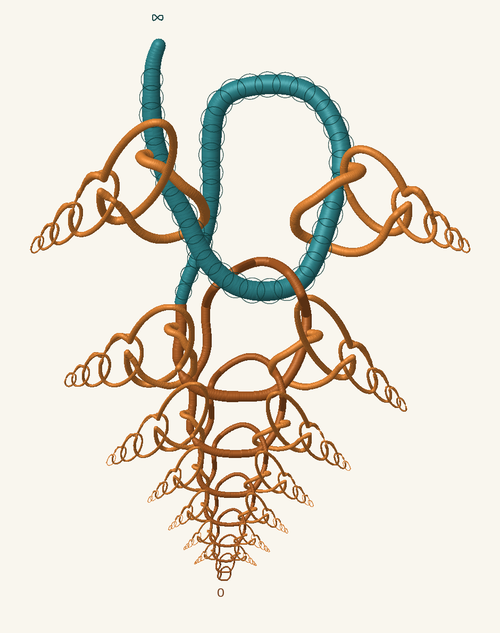

Consecutive crossings of the main loops


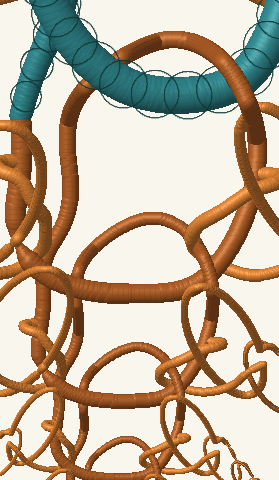

Right side chain


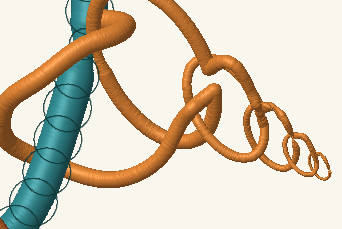

In [9]:
DEPTH = 8 #  Depth must be between 1 and 8
BEADS = True

strips = build_model(depth=DEPTH)
check_connections(strips)
check_threading(strips)

front_view = render(strips, 1.0, beads=BEADS)
display(front_view.resize((500, 633), Image.Resampling.LANCZOS))

ox, oy = OFFSET[:2].astype(int)
for title, (left, top, right, bottom) in (("Consecutive crossings of the main loops", (274, 432, 553, 912)),
                                          ("Right side chain", (508, 275, 850, 504))):
        print(title)
        display(front_view.crop((left + ox, top + oy, right + ox, bottom + oy)))

### Growth and camera orbit

Over 13 seconds, the model grows from a ball as the camera completes one full turn.

In [13]:
def shot_at(elapsed, seconds):
    """Growth and a single full turn share the same active interval"""
    u = float(np.clip((elapsed - 0.35) / (seconds - 1.45), 0.0, 1.0))
    growth = u * u * (3 - 2 * u)
    # Camera accelerates gently, turns at constant speed, then comes to rest
    ramp = 0.12
    if u < ramp:
        angle_fraction = u * u / (2 * ramp * (1 - ramp))
    elif u > 1 - ramp:
        angle_fraction = 1 - (1 - u) ** 2 / (2 * ramp * (1 - ramp))
    else:
        angle_fraction = (u - ramp / 2) / (1 - ramp)
    yaw = 360 * angle_fraction
    fade = np.clip(1 - min(yaw, 360 - yaw) / 17, 0.0, 1.0)
    opacity = float(fade * fade * (3 - 2 * fade))
    return growth, yaw, opacity

def orbit_framing(strips):
    points = np.concatenate([s.points for s in strips])
    radii = np.concatenate([s.radius for s in strips])
    pivot = np.array([WIDTH / 2, HEIGHT / 2, (points[:, 2].min() + points[:, 2].max()) / 2])
    horizontal = (points - pivot)[:, [0, 2]]
    def zoom_at(yaw):
        angle = np.deg2rad(yaw)
        extent = np.max(np.abs(horizontal @ [np.cos(angle), np.sin(angle)]) + radii)
        ratio = extent / (WIDTH / 2 - 22)
        blend = 0.045
        if ratio <= 1 - blend:
            return 1.0
        if ratio >= 1 + blend:
            return 1 / ratio
        return 1 / (1 + (ratio - 1 + blend) ** 2 / (4 * blend))
    return pivot, zoom_at

def show_animation(strips, *, beads, seconds=13, fps=24):
    """Encode rendered frames in memory and display them in the cell"""
    pivot, zoom_at = orbit_framing(strips)
    buffer = BytesIO()
    with av.open(buffer, mode="w", format="mp4") as container:
        stream = container.add_stream("libx264", rate=fps)
        stream.width, stream.height = WIDTH, HEIGHT
        stream.pix_fmt = "yuv420p"
        stream.options = {"crf": "19", "preset": "fast"}
        previous_shot = None
        for index in range(round(seconds * fps)):
            shot = shot_at(index / fps, seconds)
            if shot != previous_shot:
                growth, yaw, opacity = shot
                pixels = np.asarray(render(strips, growth,
                                           beads=beads, yaw=yaw, zoom=zoom_at(yaw),
                                           center=pivot, annotations=opacity))
                previous_shot = shot
            frame = av.VideoFrame.from_ndarray(pixels, format="rgb24")
            for packet in stream.encode(frame):
                container.mux(packet)
        for packet in stream.encode():
            container.mux(packet)
    display(Video(data=buffer.getvalue(), embed=True, mimetype="video/mp4", width=500))




show_animation(strips, beads=BEADS)

### Another angle or moment

Set the growth parameter $t$ between 0 and 1. The guide circles and endpoint labels appear in the front view

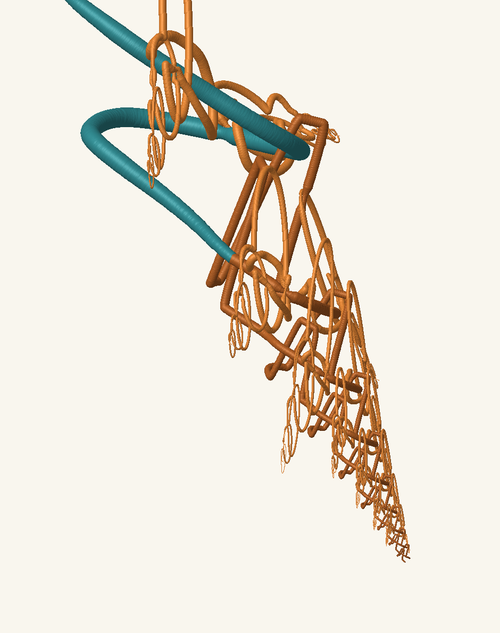

In [29]:
T, YAW, PITCH = 1.0, 67, 67

view = render(strips, T, beads=BEADS, yaw=YAW, pitch=PITCH)
display(view.resize((500, 633), Image.Resampling.LANCZOS))